# Traffic-Based Next-Road Prediction — Visualizations

## Objective

This notebook visualizes the results of the Shenzhen next-road prediction study.

The ficus is on:
- Road-network structure and geographical coverage.
- Distributions of predicted turning probabilities.
- Historical, adaptive, and LightGBM prediction comparisons.
- Highway-exit behavior and location-specific case studies.
- Model performance and limitations.

All visualizations use previously prepared datasets and the trained
LightGBM model. No model retraining is performed.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import joblib

# Locate the project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ev_traffic import features
from ev_traffic.evaluation import normalize_candidate_scores

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "shenzhen"
CACHE_DIR = PROJECT_ROOT / "data" / "processed" / "shenzhen"
MODEL_PATH = PROJECT_ROOT / "models" / "shenzhen_lightgbm.joblib"

print("Project root:", PROJECT_ROOT)
print("Raw data exists:", DATA_DIR.exists())
print("Cached data exists:", CACHE_DIR.exists())
print("Saved model exists:", MODEL_PATH.exists())

Project root: C:\Users\EAG28\OneDrive\Документы\2026W\Project\ev-traffic-charging-prediction
Raw data exists: True
Cached data exists: True
Saved model exists: True


In [2]:
# Load the datasets needed for visualizations
dataset_names = [
    "test_movements",
    "turn_options",
    "reference_baseline",
    "reference_hourly",
    "highway_movements",
]

datasets = {}

for name in dataset_names:
    with open(CACHE_DIR / f"{name}.pkl", "rb") as f:
        datasets[name] = pickle.load(f)

    print(f"{name}: {len(datasets[name]):,} rows")

# Load the trained model
lightgbm_model = joblib.load(MODEL_PATH)

# Load road-network information
edges = pd.read_csv(DATA_DIR / "edge_shenzhen.csv")
nodes = pd.read_csv(DATA_DIR / "node_shenzhen.csv")

print(f"\nRoad edges: {len(edges):,}")
print(f"Road nodes: {len(nodes):,}")
print(f"LightGBM features: {lightgbm_model.n_features_in_}")
print("\nAll visualization inputs loaded successfully!")

test_movements: 2,167,081 rows
turn_options: 72,495 rows
reference_baseline: 72,495 rows
reference_hourly: 724,950 rows
highway_movements: 39,282 rows

Road edges: 27,410
Road nodes: 11,933
LightGBM features: 14

All visualization inputs loaded successfully!


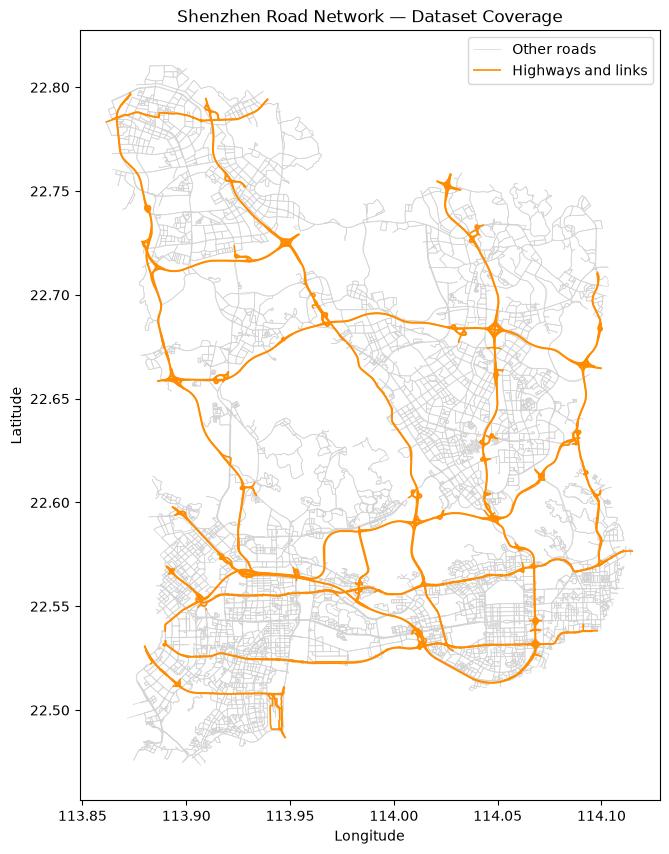

Other road segments: 25922
Highway segments: 1488


In [ ]:
from matplotlib.collections import LineCollection

# Parse road geometries into longitude/latitude coordinates
def parse_geometry(geometry):
    return [
        tuple(map(float, point.split("-")))
        for point in geometry.split("_")
    ]

highway_classes = {
    "motorway", "motorway_link",
    "trunk", "trunk_link"
}

road_segments = []
highway_segments = []

for row in edges.itertuples(index=False):
    if pd.isna(row.Geometry):
        continue

    coordinates = parse_geometry(row.Geometry)

    if len(coordinates) < 2:
        continue

    if row.Class in highway_classes:
        highway_segments.append(coordinates)
    else:
        road_segments.append(coordinates)

fig, ax = plt.subplots(figsize=(12, 10))

ax.add_collection(
    LineCollection(
        road_segments,
        colors="lightgray",
        linewidths=0.5,
        label="Other roads"
    )
)

ax.add_collection(
    LineCollection(
        highway_segments,
        colors="darkorange",
        linewidths=1.2,
        label="Highways and links"
    )
)

ax.autoscale()
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Shenzhen Road Network - Dataset Coverage")
ax.legend()
plt.show()

print("Other road segments:", len(road_segments))
print("Highway segments:", len(highway_segments))

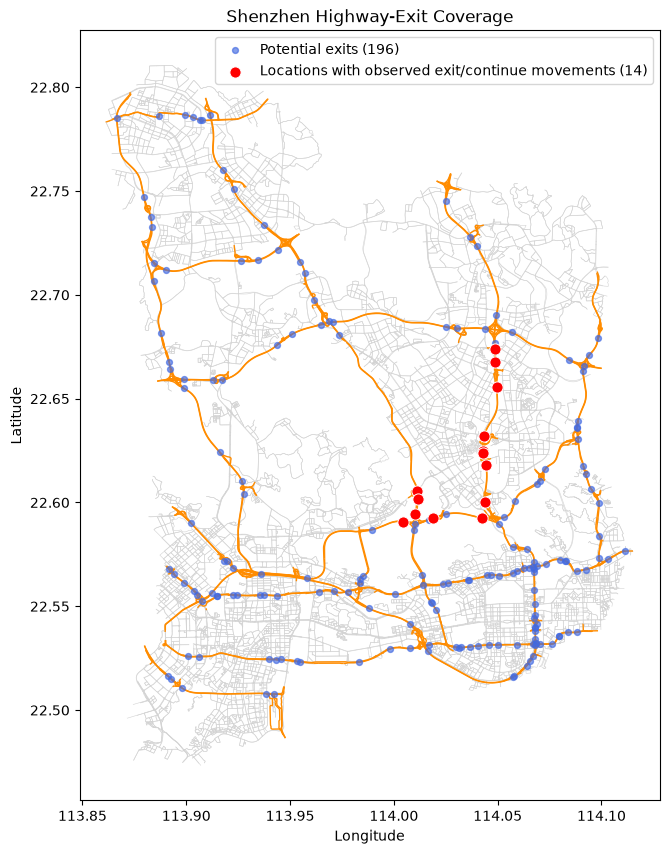

Potential exit locations: 196
Locations with classified highway movements: 14


In [5]:
from ev_traffic.network import find_highway_exit_candidates

# Identify potential highway exits
highway_exit_candidates = find_highway_exit_candidates(edges)

# Select observed highway exit/continuation movements
observed_highway = datasets["highway_movements"].loc[
    datasets["highway_movements"]["highway_action"].isin(
        ["exit", "continue"]
    )
]

observed_intersections = set(observed_highway["intersection"].unique())

# Attach geographical coordinates
potential_locations = nodes[
    nodes["NodeID"].isin(highway_exit_candidates)
]

observed_locations = nodes[
    nodes["NodeID"].isin(observed_intersections)
]

fig, ax = plt.subplots(figsize=(12, 10))

ax.add_collection(
    LineCollection(
        road_segments,
        colors="lightgray",
        linewidths=0.4
    )
)

ax.add_collection(
    LineCollection(
        highway_segments,
        colors="darkorange",
        linewidths=1.0
    )
)

ax.scatter(
    potential_locations["Longitude"],
    potential_locations["Latitude"],
    s=18,
    color="royalblue",
    alpha=0.65,
    label=f"Potential exits ({len(potential_locations)})",
    zorder=3
)

ax.scatter(
    observed_locations["Longitude"],
    observed_locations["Latitude"],
    s=65,
    color="red",
    edgecolors="white",
    linewidths=0.7,
    label=f"Locations with observed exit/continue movements ({len(observed_locations)})",
    zorder=4
)

ax.autoscale()
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Shenzhen Highway-Exit Coverage")
ax.legend()

plt.show()

print("Potential exit locations:", len(potential_locations))
print("Locations with classified highway movements:", len(observed_locations))

In [6]:
test_movements = datasets["test_movements"]

# Reproduce the original test sample
test_sample = test_movements.sample(
    n=10_000,
    random_state=42
).copy()

# Build history from the complete test set
test_history = features.build_trajectory_history(test_movements)

sample_history = test_history.loc[
    test_sample.index,
    ["previous_road_1", "previous_road_2", "trip_position"]
].reset_index(drop=True)

sample_history["movement_id"] = np.arange(len(sample_history))

# Generate candidates and features
test_candidates = features.build_candidates(
    test_sample,
    datasets["turn_options"],
    datasets["reference_baseline"]
)

test_candidates = features.attach_hourly_features(
    test_candidates,
    datasets["reference_hourly"]
)

test_candidates = features.attach_history_features(
    test_candidates,
    sample_history
)

# Predict and normalize probabilities
model_scores = lightgbm_model.predict_proba(
    test_candidates[lightgbm_model.feature_name_]
)[:, 1]

test_candidates["model_probability"] = (
    model_scores
    / pd.Series(
        model_scores, index=test_candidates.index
    ).groupby(test_candidates["movement_id"]).transform("sum")
)

# Validate predictions
probability_sums = test_candidates.groupby("movement_id")[
    "model_probability"
].sum()

print("Sampled movements:", len(test_sample))
print("Candidate turns:", len(test_candidates))
print("Probabilities sum to 1:", np.allclose(probability_sums, 1.0))
print("Exactly one chosen road per movement:",
      test_candidates.groupby("movement_id")["chosen"].sum().eq(1).all())

Sampled movements: 10000
Candidate turns: 26171
Probabilities sum to 1: True
Exactly one chosen road per movement: True


In [7]:
test_movements = datasets["test_movements"]

# Reproduce the original test sample
test_sample = test_movements.sample(
    n=10_000,
    random_state=42
).copy()

# Build history from the complete test set
test_history = features.build_trajectory_history(test_movements)

sample_history = test_history.loc[
    test_sample.index,
    ["previous_road_1", "previous_road_2", "trip_position"]
].reset_index(drop=True)

sample_history["movement_id"] = np.arange(len(sample_history))

# Generate candidates and features
test_candidates = features.build_candidates(
    test_sample,
    datasets["turn_options"],
    datasets["reference_baseline"]
)

test_candidates = features.attach_hourly_features(
    test_candidates,
    datasets["reference_hourly"]
)

test_candidates = features.attach_history_features(
    test_candidates,
    sample_history
)

# Predict and normalize probabilities
model_scores = lightgbm_model.predict_proba(
    test_candidates[lightgbm_model.feature_name_]
)[:, 1]

test_candidates["model_probability"] = (
    model_scores
    / pd.Series(
        model_scores, index=test_candidates.index
    ).groupby(test_candidates["movement_id"]).transform("sum")
)

# Validate predictions
probability_sums = test_candidates.groupby("movement_id")[
    "model_probability"
].sum()

print("Sampled movements:", len(test_sample))
print("Candidate turns:", len(test_candidates))
print("Probabilities sum to 1:", np.allclose(probability_sums, 1.0))
print("Exactly one chosen road per movement:",
      test_candidates.groupby("movement_id")["chosen"].sum().eq(1).all())

Sampled movements: 10000
Candidate turns: 26171
Probabilities sum to 1: True
Exactly one chosen road per movement: True


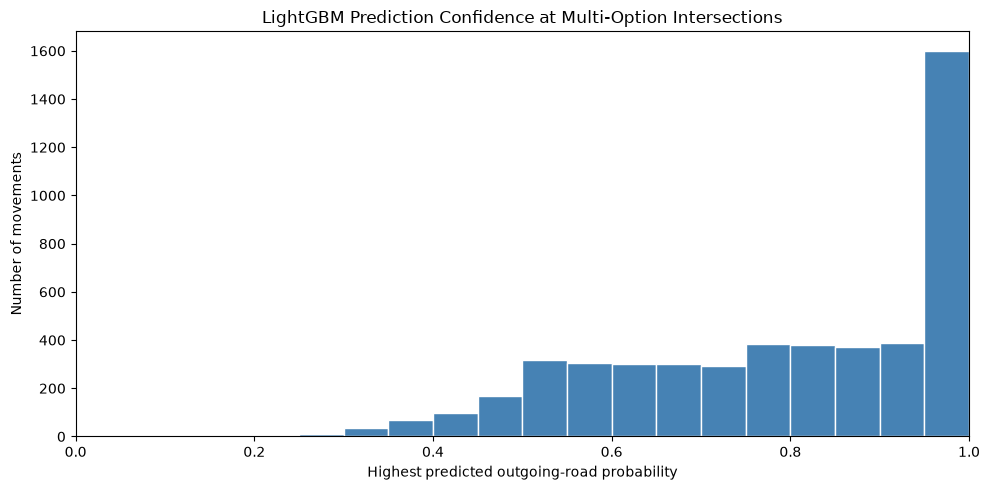

Movements with at least 3 options: 5019
Median maximum probability: 83.2%
Share with maximum probability >= 80%: 54.6%


In [8]:
# Summarize predictions per movement
intersection_predictions = (
    test_candidates
    .groupby("movement_id")
    .agg(
        n_options=("outgoing", "count"),
        max_probability=("model_probability", "max")
    )
    .reset_index()
)

# Keep movements with at least 3 outgoing options
multi_option = intersection_predictions[
    intersection_predictions["n_options"] >= 3
].copy()

# Plot the distribution of maximum predicted probabilities
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    multi_option["max_probability"],
    bins=np.linspace(0, 1, 21),
    color="steelblue",
    edgecolor="white"
)

ax.set_title(
    "LightGBM Prediction Confidence at Multi-Option Intersections"
)
ax.set_xlabel("Highest predicted outgoing-road probability")
ax.set_ylabel("Number of movements")
ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

print("Movements with at least 3 options:", len(multi_option))
print("Median maximum probability:",
      f"{multi_option['max_probability'].median():.1%}")
print("Share with maximum probability >= 80%:",
      f"{(multi_option['max_probability'] >= 0.8).mean():.1%}")

                  movements  mean_confidence  accuracy
confidence_group                                      
≤40%                    118            0.354     0.314
40–60%                  886            0.522     0.526
60–80%                 1275            0.704     0.706
80–100%                2740            0.943     0.947


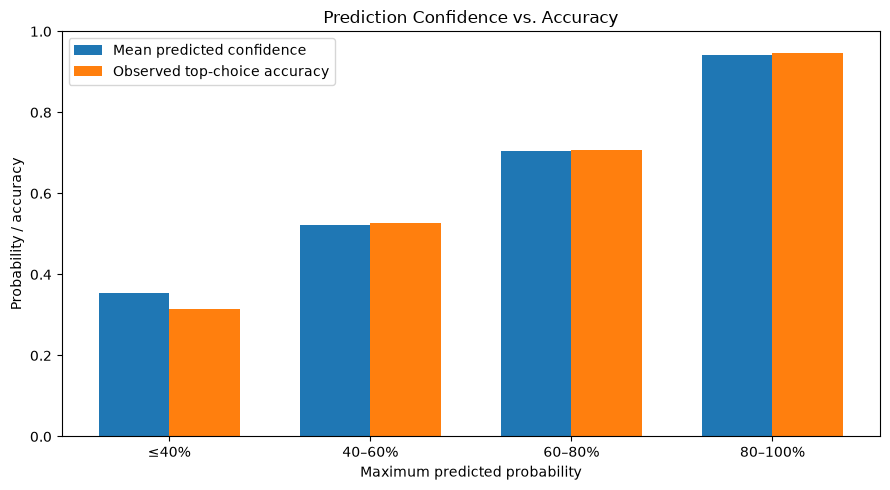

In [9]:
# Identify the highest-probability candidate for each movement
top_predictions = (
    test_candidates
    .sort_values("model_probability", ascending=False)
    .drop_duplicates(subset="movement_id")
    .copy()
)

# Restrict to movements with at least 3 outgoing options
top_predictions = top_predictions.merge(
    multi_option[["movement_id", "n_options"]],
    on="movement_id",
    how="inner",
    validate="one_to_one"
)

# Group predictions by confidence
top_predictions["confidence_group"] = pd.cut(
    top_predictions["model_probability"],
    bins=[0, 0.4, 0.6, 0.8, 1.0],
    labels=["≤40%", "40–60%", "60–80%", "80–100%"],
    include_lowest=True
)

confidence_summary = (
    top_predictions
    .groupby("confidence_group", observed=True)
    .agg(
        movements=("movement_id", "count"),
        mean_confidence=("model_probability", "mean"),
        accuracy=("chosen", "mean")
    )
)

print(confidence_summary.to_string(
    float_format=lambda x: f"{x:.3f}"
))

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(confidence_summary))
width = 0.35

ax.bar(
    x - width / 2,
    confidence_summary["mean_confidence"],
    width,
    label="Mean predicted confidence"
)

ax.bar(
    x + width / 2,
    confidence_summary["accuracy"],
    width,
    label="Observed top-choice accuracy"
)

ax.set_xticks(x)
ax.set_xticklabels(confidence_summary.index)
ax.set_ylim(0, 1)
ax.set_ylabel("Probability / accuracy")
ax.set_xlabel("Maximum predicted probability")
ax.set_title("Prediction Confidence vs. Accuracy")
ax.legend()

plt.tight_layout()
plt.show()

In [10]:
# Attach road classifications to candidate outgoing roads
road_classes = (
    edges[["Origin", "Destination", "Class"]]
    .drop_duplicates(subset=["Origin", "Destination"])
    .rename(columns={"Class": "outgoing_class"})
)

actual_turns = test_candidates.loc[
    test_candidates["chosen"] == 1
].merge(
    road_classes,
    left_on=["intersection", "outgoing"],
    right_on=["Origin", "Destination"],
    how="left",
    validate="many_to_one"
).copy()

# Calculate log loss for the actual outgoing road
actual_turns["adaptive_loss"] = -np.log(
    actual_turns["adaptive_probability"].clip(lower=1e-15)
)

actual_turns["model_loss"] = -np.log(
    actual_turns["model_probability"].clip(lower=1e-15)
)

# Summarize performance by road class
road_class_performance = (
    actual_turns.groupby("outgoing_class")
    .agg(
        movements=("movement_id", "count"),
        adaptive_loss=("adaptive_loss", "mean"),
        model_loss=("model_loss", "mean")
    )
)

road_class_performance["improvement_pct"] = (
    (road_class_performance["adaptive_loss"]
     - road_class_performance["model_loss"])
    / road_class_performance["adaptive_loss"]
    * 100
)

road_class_performance = road_class_performance.sort_values(
    "movements", ascending=False
)

print(road_class_performance.round(4).to_string())
print("\nUnmatched road classes:",
      actual_turns["outgoing_class"].isna().sum())

                movements  adaptive_loss  model_loss  improvement_pct
outgoing_class                                                       
secondary            3632         0.2947      0.2679           9.0674
tertiary             3226         0.3830      0.3500           8.6209
primary              2138         0.2038      0.1949           4.3356
primary_link          210         0.3148      0.3057           2.8907
trunk                 191         0.2375      0.2150           9.4783
residential           174         0.6983      0.7566          -8.3528
secondary_link        112         0.6146      0.5174          15.8083
unclassified           91         0.6186      0.5482          11.3822
motorway               73         0.2179      0.1494          31.4635
motorway_link          54         0.4605      0.4423           3.9484
tertiary_link          52         0.4544      0.5104         -12.3062
trunk_link             46         0.1243      0.1227           1.2538
living_street       

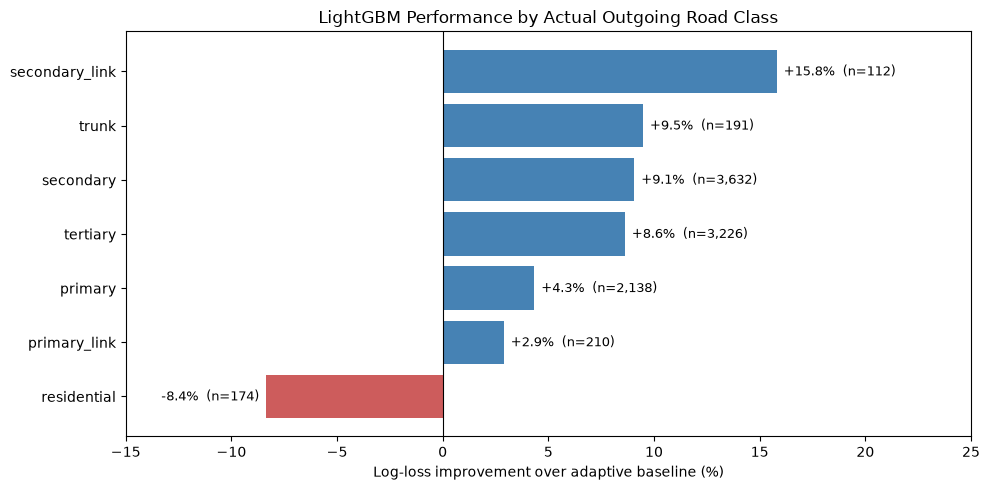

In [11]:
# Restrict visualization to road classes with sufficient observations
plot_data = (
    road_class_performance[
        road_class_performance["movements"] >= 100
    ]
    .sort_values("improvement_pct")
)

fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    "steelblue" if improvement >= 0 else "indianred"
    for improvement in plot_data["improvement_pct"]
]

bars = ax.barh(
    plot_data.index,
    plot_data["improvement_pct"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)

for bar, count in zip(bars, plot_data["movements"]):
    value = bar.get_width()
    ax.annotate(
        f"{value:+.1f}%  (n={count:,})",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Log-loss improvement over adaptive baseline (%)")
ax.set_title("LightGBM Performance by Actual Outgoing Road Class")
ax.set_xlim(
    min(-15, plot_data["improvement_pct"].min() - 5),
    max(25, plot_data["improvement_pct"].max() + 5)
)

plt.tight_layout()
plt.show()

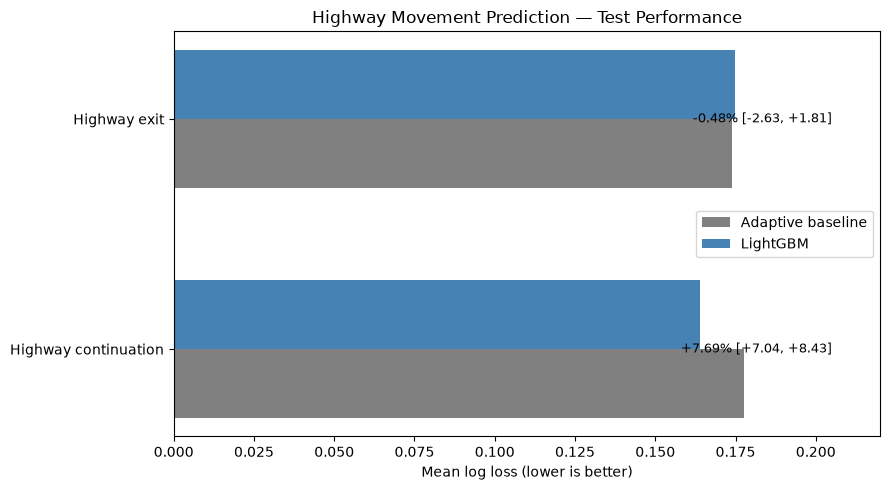

In [12]:
highway_performance = pd.DataFrame({
    "Movement type": ["Highway continuation", "Highway exit"],
    "Adaptive baseline": [0.1777, 0.1740],
    "LightGBM": [0.1640, 0.1749],
    "Improvement (%)": [7.69, -0.48],
    "CI lower (%)": [7.04, -2.63],
    "CI upper (%)": [8.43, 1.81],
    "Movements": [1941, 3300]
})

fig, ax = plt.subplots(figsize=(9, 5))

y = np.arange(len(highway_performance))
height = 0.3

ax.barh(
    y - height / 2,
    highway_performance["Adaptive baseline"],
    height,
    label="Adaptive baseline",
    color="gray"
)

ax.barh(
    y + height / 2,
    highway_performance["LightGBM"],
    height,
    label="LightGBM",
    color="steelblue"
)

ax.set_yticks(y)
ax.set_yticklabels(highway_performance["Movement type"])
ax.set_xlabel("Mean log loss (lower is better)")
ax.set_title("Highway Movement Prediction — Test Performance")
ax.legend()

ax.set_xlim(0, 0.22)

for i, row in highway_performance.iterrows():
    ax.text(
        0.205,
        i,
        f"{row['Improvement (%)']:+.2f}% "
        f"[{row['CI lower (%)']:+.2f}, {row['CI upper (%)']:+.2f}]",
        ha="right",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

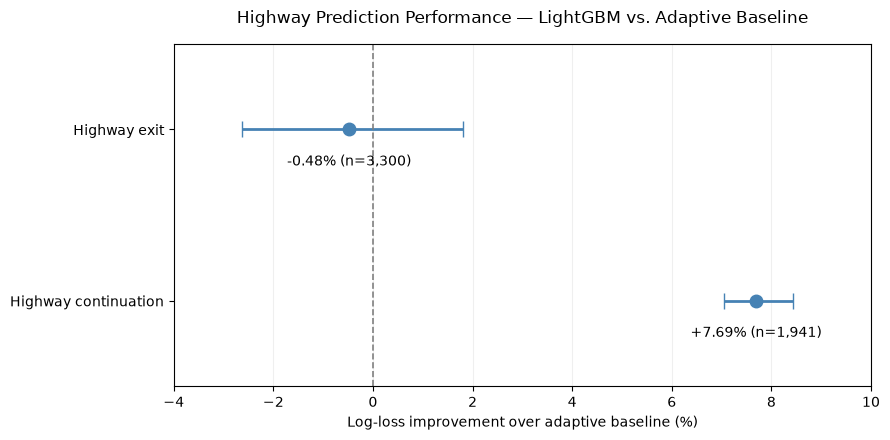

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))

# Position the two categories with enough vertical spacing
y = np.array([0, 1])

improvement = highway_performance["Improvement (%)"].to_numpy()
lower = highway_performance["CI lower (%)"].to_numpy()
upper = highway_performance["CI upper (%)"].to_numpy()

ax.errorbar(
    improvement,
    y,
    xerr=[improvement - lower, upper - improvement],
    fmt="o",
    markersize=9,
    capsize=6,
    linewidth=2,
    color="steelblue"
)

# Reference line: zero improvement
ax.axvline(0, color="gray", linestyle="--", linewidth=1.2)

# Category labels
ax.set_yticks(y)
ax.set_yticklabels(highway_performance["Movement type"])

# Add vertical padding so annotations stay inside the plot
ax.set_ylim(-0.5, 1.5)

# Place annotations below the points
for i, row in highway_performance.iterrows():
    ax.annotate(
        f"{row['Improvement (%)']:+.2f}% (n={row['Movements']:,})",
        xy=(row["Improvement (%)"], i),
        xytext=(0, -18),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=10
    )

ax.set_xlim(-4, 10)
ax.set_xlabel("Log-loss improvement over adaptive baseline (%)")
ax.set_title("Highway Prediction Performance — LightGBM vs. Adaptive Baseline", pad=15)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

 incoming  intersection  movements  exits  continuations  exit_rate     approach
     8402           361        873    873              0   1.000000   8402 → 361
    11622            74        806    324            482   0.401985   11622 → 74
     4339          3841        708    707              1   0.998588  4339 → 3841
    11775          1093        643    643              0   1.000000 11775 → 1093
     1097          1098        585    122            463   0.208547  1097 → 1098
     8886          1090        482      0            482   0.000000  8886 → 1090
     1102          1103        458    458              0   1.000000  1102 → 1103
    11621           360        288      0            288   0.000000  11621 → 360
    11648          3806        165    165              0   1.000000 11648 → 3806
     8270          8277        165      0            165   0.000000  8270 → 8277
    11622           937         33      7             26   0.212121  11622 → 937
     8885          1094     

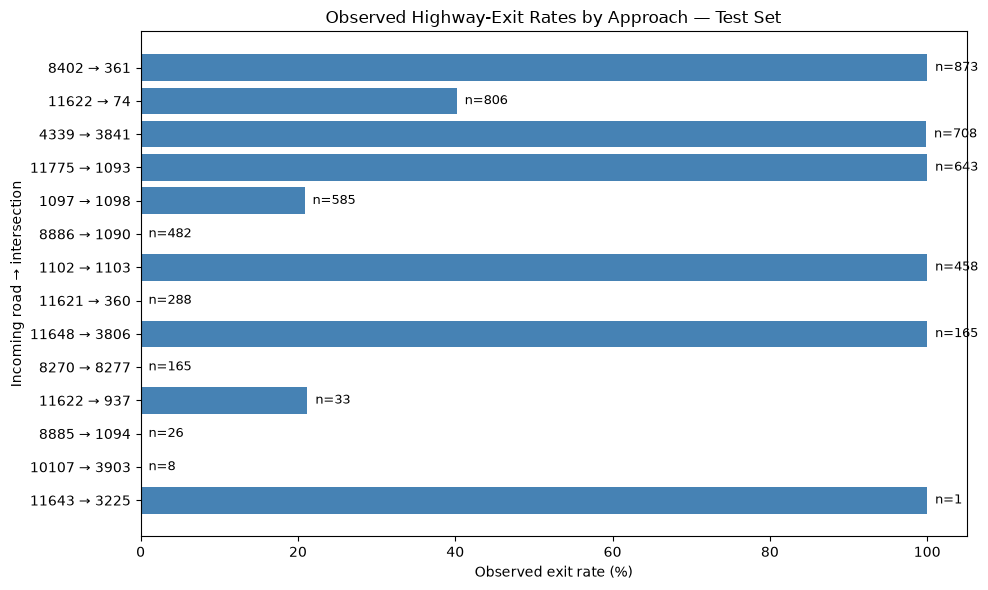

In [15]:
highway_test = datasets["highway_movements"].loc[
    (datasets["highway_movements"]["split"] == "test")
    & (datasets["highway_movements"]["highway_action"].isin(
        ["exit", "continue"]
    ))
].copy()

exit_summary = (
    highway_test
    .groupby(["incoming", "intersection"])
    .agg(
        movements=("highway_action", "size"),
        exits=("highway_action", lambda x: (x == "exit").sum()),
        continuations=("highway_action", lambda x: (x == "continue").sum())
    )
    .reset_index()
)

exit_summary["exit_rate"] = (
    exit_summary["exits"] / exit_summary["movements"]
)

exit_summary["approach"] = (
    exit_summary["incoming"].astype(str)
    + " → "
    + exit_summary["intersection"].astype(str)
)

exit_summary = exit_summary.sort_values(
    "movements", ascending=False
)

print(exit_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    exit_summary["approach"],
    exit_summary["exit_rate"] * 100,
    color="steelblue"
)

ax.set_xlabel("Observed exit rate (%)")
ax.set_ylabel("Incoming road → intersection")
ax.set_title("Observed Highway-Exit Rates by Approach — Test Set")
ax.set_xlim(0, 105)
ax.invert_yaxis()

for i, row in enumerate(exit_summary.itertuples()):
    ax.text(
        row.exit_rate * 100 + 1,
        i,
        f"n={row.movements:,}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

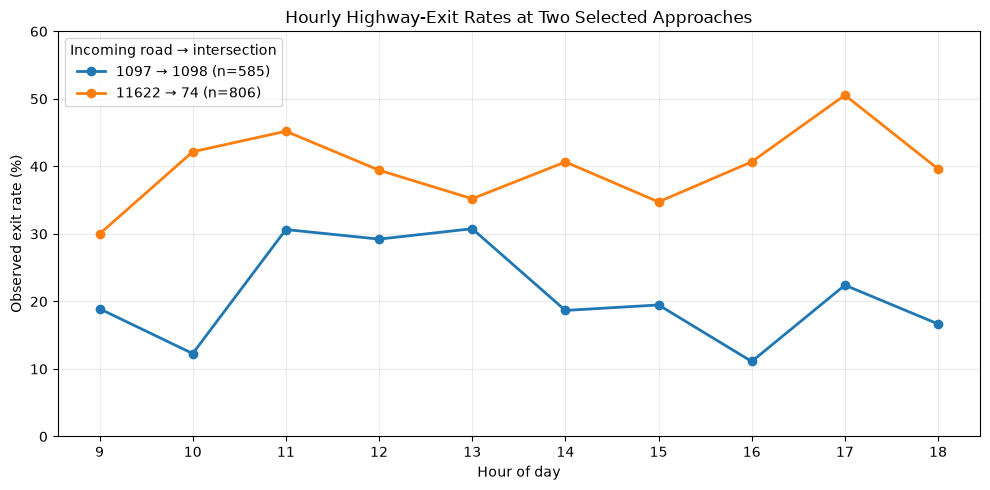

   approach  hour  movements  exits  exit_rate
1097 → 1098     9         37      7   0.189189
1097 → 1098    10         57      7   0.122807
1097 → 1098    11         62     19   0.306452
1097 → 1098    12         65     19   0.292308
1097 → 1098    13         52     16   0.307692
1097 → 1098    14         75     14   0.186667
1097 → 1098    15         77     15   0.194805
1097 → 1098    16         90     10   0.111111
1097 → 1098    17         58     13   0.224138
1097 → 1098    18         12      2   0.166667
 11622 → 74     9         60     18   0.300000
 11622 → 74    10         83     35   0.421687
 11622 → 74    11         73     33   0.452055
 11622 → 74    12         71     28   0.394366
 11622 → 74    13         71     25   0.352113
 11622 → 74    14         91     37   0.406593
 11622 → 74    15         95     33   0.347368
 11622 → 74    16        118     48   0.406780
 11622 → 74    17         91     46   0.505495
 11622 → 74    18         53     21   0.396226

Total select

In [17]:
# Explicitly select the two well-represented highway approaches
selected_approaches = pd.DataFrame({
    "incoming": [1097, 11622],
    "intersection": [1098, 74]
})

mixed_highway = highway_test.merge(
    selected_approaches,
    on=["incoming", "intersection"],
    how="inner",
    validate="many_to_one"
).copy()

mixed_highway["approach"] = (
    mixed_highway["incoming"].astype(str)
    + " → "
    + mixed_highway["intersection"].astype(str)
)

hourly_exit = (
    mixed_highway
    .groupby(["approach", "hour"])
    .agg(
        movements=("highway_action", "size"),
        exits=("highway_action", lambda x: (x == "exit").sum())
    )
    .reset_index()
)

hourly_exit["exit_rate"] = (
    hourly_exit["exits"] / hourly_exit["movements"]
)

fig, ax = plt.subplots(figsize=(10, 5))

for approach, group in hourly_exit.groupby("approach"):
    ax.plot(
        group["hour"],
        group["exit_rate"] * 100,
        marker="o",
        linewidth=2,
        label=f"{approach} (n={group['movements'].sum():,})"
    )

ax.set_xlabel("Hour of day")
ax.set_ylabel("Observed exit rate (%)")
ax.set_title("Hourly Highway-Exit Rates at Two Selected Approaches")
ax.set_xticks(sorted(hourly_exit["hour"].unique()))
ax.set_ylim(0, 60)
ax.legend(title="Incoming road → intersection")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(hourly_exit.to_string(index=False))
print("\nTotal selected movements:", len(mixed_highway))

In [18]:
case_studies = [
    (1097, 1098, 938, 1099),
    (11622, 74, 75, 76)
]

for incoming, intersection, exit_road, continue_road in case_studies:
    print(f"\nApproach: {incoming} → {intersection}")

    for origin, destination, role in [
        (incoming, intersection, "Incoming highway"),
        (intersection, exit_road, "Exit link"),
        (intersection, continue_road, "Highway continuation")
    ]:
        road = edges.loc[
            (edges["Origin"] == origin)
            & (edges["Destination"] == destination)
        ]

        if road.empty:
            print(f"  {role}: {origin} → {destination} NOT FOUND")
        else:
            print(
                f"  {role}: {origin} → {destination}, "
                f"class={road.iloc[0]['Class']}, "
                f"length={road.iloc[0]['Length']:.1f} m"
            )

    node = nodes.loc[nodes["NodeID"] == intersection]

    if not node.empty:
        print(
            f"  Intersection coordinates: "
            f"{node.iloc[0]['Longitude']:.6f}, "
            f"{node.iloc[0]['Latitude']:.6f}"
        )


Approach: 1097 → 1098
  Incoming highway: 1097 → 1098, class=motorway, length=1801.6 m
  Exit link: 1098 → 938, class=motorway_link, length=335.9 m
  Highway continuation: 1098 → 1099, class=motorway, length=624.4 m
  Intersection coordinates: 114.044402, 22.617994

Approach: 11622 → 74
  Incoming highway: 11622 → 74, class=motorway, length=52.7 m
  Exit link: 74 → 75, class=motorway_link, length=420.2 m
  Highway continuation: 74 → 76, class=motorway, length=779.7 m
  Intersection coordinates: 114.043011, 22.624879


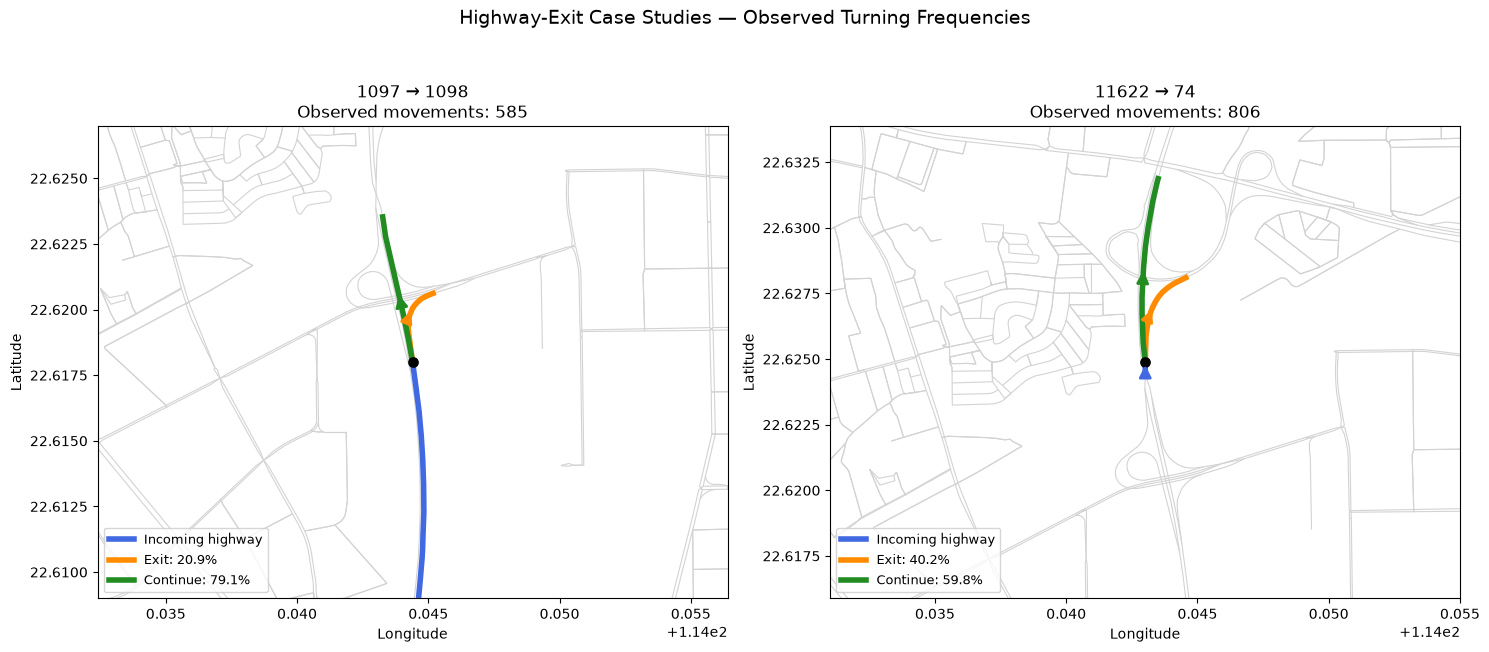

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

case_studies = [
    {
        "incoming": 1097,
        "intersection": 1098,
        "exit": 938,
        "continue": 1099,
        "exit_rate": 122 / 585,
        "n": 585
    },
    {
        "incoming": 11622,
        "intersection": 74,
        "exit": 75,
        "continue": 76,
        "exit_rate": 324 / 806,
        "n": 806
    }
]

for ax, case in zip(axes, case_studies):
    center = nodes.loc[
        nodes["NodeID"] == case["intersection"]
    ].iloc[0]

    lon, lat = center["Longitude"], center["Latitude"]

    # Approximate 1 km viewing radius
    lon_radius = 0.012
    lat_radius = 0.009

    # Surrounding road network
    nearby_edges = edges[
        edges["Geometry"].apply(
            lambda g: (
                isinstance(g, str)
                and any(
                    abs(x - lon) < lon_radius * 1.5
                    and abs(y - lat) < lat_radius * 1.5
                    for x, y in parse_geometry(g)
                )
            )
        )
    ]

    background_segments = [
        parse_geometry(g)
        for g in nearby_edges["Geometry"]
    ]

    ax.add_collection(
        LineCollection(
            background_segments,
            colors="lightgray",
            linewidths=0.8,
            zorder=1
        )
    )

    # Highlight the three relevant roads
    connections = [
        (case["incoming"], case["intersection"],
         "Incoming highway", "royalblue"),
        (case["intersection"], case["exit"],
         f"Exit: {case['exit_rate']:.1%}", "darkorange"),
        (case["intersection"], case["continue"],
         f"Continue: {1 - case['exit_rate']:.1%}", "forestgreen")
    ]

    for origin, destination, label, color in connections:
        road = edges.loc[
            (edges["Origin"] == origin)
            & (edges["Destination"] == destination)
        ].iloc[0]

        coords = parse_geometry(road["Geometry"])
        xs, ys = zip(*coords)

        ax.plot(
            xs, ys,
            color=color,
            linewidth=4,
            label=label,
            zorder=3
        )

    # Add directional arrows along highlighted roads
    for origin, destination, label, color in connections:
        road = edges.loc[
            (edges["Origin"] == origin)
            & (edges["Destination"] == destination)
        ].iloc[0]

        coords = parse_geometry(road["Geometry"])

        # Choose a segment near the middle of the road
        midpoint = max(0, (len(coords) - 2) // 2)
        x1, y1 = coords[midpoint]
        x2, y2 = coords[midpoint + 1]

        ax.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops={
                "arrowstyle": "-|>",
                "color": color,
                "lw": 2,
                "mutation_scale": 18
            },
            zorder=5
        )
    ax.scatter(
        lon, lat,
        color="black",
        s=45,
        zorder=4
    )

    ax.set_xlim(lon - lon_radius, lon + lon_radius)
    ax.set_ylim(lat - lat_radius, lat + lat_radius)
    ax.set_aspect("equal")
    ax.set_title(
        f"{case['incoming']} → {case['intersection']}\n"
        f"Observed movements: {case['n']:,}"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="lower left", fontsize=9)

plt.suptitle(
    "Highway-Exit Case Studies — Observed Turning Frequencies",
    fontsize=14
)
plt.tight_layout()
plt.show()

In [22]:
from IPython.display import display

# Use the same 5 sampled movements
examples = test_candidates[
    test_candidates["movement_id"].isin(example_ids)
].copy()

prediction_table = examples[
    [
        "movement_id",
        "incoming",
        "intersection",
        "hour",
        "outgoing",
        "adaptive_probability",
        "model_probability",
        "chosen"
    ]
].copy()

prediction_table = prediction_table.rename(columns={
    "movement_id": "Movement",
    "incoming": "Incoming road",
    "intersection": "Intersection",
    "hour": "Hour",
    "outgoing": "Possible next road",
    "adaptive_probability": "Adaptive (%)",
    "model_probability": "LightGBM (%)",
    "chosen": "Actual choice"
})

prediction_table["Adaptive (%)"] *= 100
prediction_table["LightGBM (%)"] *= 100

prediction_table["Actual choice"] = prediction_table[
    "Actual choice"
].map({1: "✓ Yes", 0: "No"})

prediction_table = prediction_table.sort_values(
    ["Movement", "LightGBM (%)"],
    ascending=[True, False]
)

display(
    prediction_table.style
    .format({
        "Adaptive (%)": "{:.1f}",
        "LightGBM (%)": "{:.1f}"
    })
    .highlight_max(
        subset=["LightGBM (%)"],
        color="#dceaf7",
        axis=0
    )
    .hide(axis="index")
)

Movement,Incoming road,Intersection,Hour,Possible next road,Adaptive (%),LightGBM (%),Actual choice
2319,6770,6663,12,11864,79.9,81.3,✓ Yes
2319,6770,6663,12,11871,10.7,9.6,No
2319,6770,6663,12,10532,5.3,4.9,No
2319,6770,6663,12,6768,4.1,4.1,No
4749,1254,1255,13,10260,74.4,84.7,✓ Yes
4749,1254,1255,13,6000,7.8,7.8,No
4749,1254,1255,13,1254,17.8,7.6,No
5193,8453,11710,18,1500,92.9,98.9,✓ Yes
5193,8453,11710,18,1501,7.1,1.1,No
5193,8453,11710,18,1502,0.0,0.0,No


In [23]:
def highlight_predictions(group):
    styles = pd.DataFrame(
        "", index=group.index, columns=group.columns
    )

    top_idx = group["LightGBM (%)"].idxmax()
    styles.loc[top_idx, "LightGBM (%)"] = (
        "background-color: #dceaf7; color: #17365d"
    )

    actual_idx = group.index[group["Actual choice"] == "✓ Yes"]
    styles.loc[actual_idx, "Actual choice"] = (
        "background-color: #d9f2df; color: #185c37"
    )

    return styles

display(
    prediction_table.style
    .format({
        "Adaptive (%)": "{:.1f}",
        "LightGBM (%)": "{:.1f}"
    })
    .apply(
        lambda df: pd.concat(
            [
                highlight_predictions(group)
                for _, group in df.groupby("Movement", sort=False)
            ]
        ).reindex(df.index),
        axis=None
    )
    .hide(axis="index")
)

Movement,Incoming road,Intersection,Hour,Possible next road,Adaptive (%),LightGBM (%),Actual choice
2319,6770,6663,12,11864,79.9,81.3,✓ Yes
2319,6770,6663,12,11871,10.7,9.6,No
2319,6770,6663,12,10532,5.3,4.9,No
2319,6770,6663,12,6768,4.1,4.1,No
4749,1254,1255,13,10260,74.4,84.7,✓ Yes
4749,1254,1255,13,6000,7.8,7.8,No
4749,1254,1255,13,1254,17.8,7.6,No
5193,8453,11710,18,1500,92.9,98.9,✓ Yes
5193,8453,11710,18,1501,7.1,1.1,No
5193,8453,11710,18,1502,0.0,0.0,No


In [24]:
# Aggregate predictions for every incoming-road/intersection pair
turning_probabilities = (
    test_candidates
    .groupby(["incoming", "intersection", "outgoing"])
    .agg(
        movements=("movement_id", "nunique"),
        observed_count=("chosen", "sum"),
        adaptive_probability=("adaptive_probability", "mean"),
        model_probability=("model_probability", "mean")
    )
    .reset_index()
)

# Total observed movements per approach
turning_probabilities["total_movements"] = (
    turning_probabilities
    .groupby(["incoming", "intersection"])["movements"]
    .transform("max")
)

turning_probabilities["observed_probability"] = (
    turning_probabilities["observed_count"]
    / turning_probabilities["total_movements"]
)

# Display the approaches with the most observations
top_approaches = (
    turning_probabilities
    .groupby(["incoming", "intersection"])["total_movements"]
    .first()
    .nlargest(5)
    .index
)

example_table = (
    turning_probabilities
    .set_index(["incoming", "intersection"])
    .loc[top_approaches]
    .reset_index()
)

display(
    example_table[
        [
            "incoming", "intersection", "outgoing",
            "total_movements", "observed_probability",
            "adaptive_probability", "model_probability"
        ]
    ].style.format({
        "observed_probability": "{:.1%}",
        "adaptive_probability": "{:.1%}",
        "model_probability": "{:.1%}"
    }).hide(axis="index")
)

incoming,intersection,outgoing,total_movements,observed_probability,adaptive_probability,model_probability
9241,8438,8435,49,10.2%,9.4%,8.3%
9241,8438,8439,49,61.2%,54.7%,57.4%
9241,8438,11711,49,28.6%,35.8%,34.3%
11716,1223,1224,41,24.4%,19.2%,19.1%
11716,1223,11750,41,75.6%,80.8%,80.9%
10226,11320,11318,34,0.0%,0.0%,0.0%
10226,11320,11699,34,100.0%,100.0%,100.0%
10531,6661,6662,34,41.2%,36.4%,36.4%
10531,6661,6905,34,52.9%,62.6%,62.4%
10531,6661,11741,34,5.9%,1.0%,1.2%



## Findings and Limitations

### 1. Road-network coverage

The Shenzhen road network contains 27,410 edges and 11,933 nodes, including motorways, arterial roads, and local streets.

The network analysis identified 196 potential highway-exit intersections based on road topology. However, only 15 of these intersections (7.7%) have observed movements across the complete trajectory dataset, and 14 have movements classified as highway exits or continuations.

This indicates substantial geographical differences between the road-network coverage and the available trajectory observations. The remaining 181 intersections have no recorded movements in the dataset, but this does not imply that they are unused in real traffic.

Consequently, the highway-specific findings are geographically restricted and cannot be generalized to all highway exits in Shenzhen.


### 2. Next-road prediction performance

LightGBM improves next-road prediction compared with the historical adaptive baseline.

On the held-out test sample of 10,000 movements:

- Adaptive baseline log loss: **0.3171**
- LightGBM log loss: **0.2933**
- Relative improvement: **7.52%**
- Trip-level bootstrap 95% confidence interval: **5.50% to 9.10%**

These results indicate that combining historical turning patterns with temporal and trajectory-history features improves probabilistic next-road prediction.

The confidence analysis also shows that higher-confidence predictions are generally more likely to identify the correct outgoing road. However, confident predictions can still be incorrect.

### 3. Turning probabilities across the road network

The model produces a probability distribution over possible outgoing roads for each observed movement.

By averaging predictions across movements sharing the same incoming road and intersection, we obtain interpretable, approach-level turning probabilities.

The aggregated examples demonstrate that:

- Some approaches have several outgoing roads with substantial probabilities.
- Other approaches are dominated by a single outgoing road.
- LightGBM and the adaptive baseline sometimes produce similar distributions, while at other locations their estimates differ.

These aggregated probabilities depend on the distribution of hours and trajectory histories represented in the evaluated sample. They should not be interpreted as universal turning probabilities for every vehicle or traffic condition.

### 4. Highway-exit behavior

Highway continuation and highway exit movements show different prediction outcomes.

**Highway continuation:**
- 1,941 evaluated movements
- LightGBM improves log loss by **7.69%**
- Bootstrap 95% confidence interval: **7.04% to 8.43%**

**Highway exit:**
- 3,300 evaluated movements
- LightGBM changes log loss by **-0.48%**
- Bootstrap 95% confidence interval: **-2.63% to 1.81%**

Thus, the model demonstrates a clear improvement for highway continuation movements, but **no statistically significant improvement for highway exits**.

These results evaluate next-road prediction on movements classified by their observed highway action. They do not represent the performance of a separately trained binary highway-exit classifier.

### 5. Highway case studies

Two highway approaches with substantial observations of both exiting and continuing vehicles were examined:

- **1097 → 1098:** 585 movements, with an observed exit rate of 20.9%.
- **11622 → 74:** 806 movements, with an observed exit rate of 40.2%.

The geographical visualizations illustrate the corresponding incoming motorway, exit ramp, and continuation road.

Hourly exit-rate plots show variation across the observed hours, but the available evidence is insufficient to establish systematic time-of-day effects. Some hourly groups contain relatively few movements.

### 6. Limitations

Several limitations affect the interpretation and generalizability of the results:

1. **Dataset coverage:** Observed trajectories are unevenly distributed across the network, particularly around highway exits.
2. **Sampling:** Some intersection-level probability estimates are based on relatively few test movements.
3. **Evaluation split:** Movements were split by trip rather than chronologically. The evaluation therefore does not establish performance on future days or under changing traffic conditions.
4. **Road-network representation:** Candidate outgoing roads are derived from network connectivity without explicit turn restrictions. Some candidate movements, including U-turns, may be unrealistic or affected by data artifacts.
5. **Highway-exit performance:** The current model does not demonstrate a statistically significant improvement over the adaptive baseline for highway-exit movements.
6. **Model scope:** The study predicts the next road taken by a vehicle. It does not identify electric vehicles, predict charging events, estimate charging demand, or recommend charging stations.

### 7. Conclusion

The study demonstrates that historical traffic patterns, time-of-day information, and recent trajectory history can be combined to improve probabilistic next-road prediction on the Shenzhen road network.

The trained LightGBM model outperforms the adaptive baseline overall and for highway continuation movements. However, improvements do not extend consistently to highway exits, where limited coverage and heterogeneous movement patterns remain important challenges.

The resulting turning-probability distributions provide a foundation for studying route-choice behavior. Connecting these predictions to EV charging demand would require additional information and further modeling beyond the scope of the present study.


In [25]:
potential = set(highway_exit_candidates)

all_movements = datasets["test_movements"]
highway_movements = datasets["highway_movements"]

observed_any = set(all_movements["intersection"]) & potential

observed_highway = set(
    highway_movements.loc[
        highway_movements["highway_action"].isin(["exit", "continue"]),
        "intersection"
    ]
) & potential

print("Potential highway-exit intersections:", len(potential))
print("With any test movements:", len(observed_any))
print("With classified highway movements:", len(observed_highway))
print("No test movements:", len(potential - observed_any))
print(
    "Test movements but no classified highway movements:",
    len(observed_any - observed_highway)
)

Potential highway-exit intersections: 196
With any test movements: 15
With classified highway movements: 14
No test movements: 181
Test movements but no classified highway movements: 1


In [26]:
all_movements = pd.concat(
    [
        datasets["test_movements"],
        pd.read_pickle(CACHE_DIR / "train_movements.pkl"),
        pd.read_pickle(CACHE_DIR / "validation_movements.pkl")
    ],
    ignore_index=True
)

potential = set(highway_exit_candidates)
observed_all = set(all_movements["intersection"]) & potential

print("Potential highway-exit intersections:", len(potential))
print("With movements across all splits:", len(observed_all))
print("Without movements across all splits:", len(potential - observed_all))
print("Coverage:", f"{len(observed_all) / len(potential):.1%}")

Potential highway-exit intersections: 196
With movements across all splits: 15
Without movements across all splits: 181
Coverage: 7.7%
